# 1.4: Drawing shapes

We start by importing our prior solutions into Python:

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Reasonable order of magnitude estimates:
r_m = 0.006
L_m = 0.003
R_m = 1.5
J_m = 5*10**(-5)
K_m = 0.1
m = 0.5
mu_x = 10
mu_y = 10

A_x = np.array([[-mu_x / (2*J_m / r_m**2 + m),        0,     r_m*K_m / (2*J_m + m*r_m**2)],
                [1,                                   0,                   0],
                [(-2*K_m / r_m) / L_m,                0,              -R_m / L_m]])

A_y = np.array([[-mu_y / (2*J_m / r_m**2 + m),        0,     r_m*K_m / (2*J_m + m*r_m**2)],
                [1,                                   0,                   0],
                [(-2*K_m / r_m) / L_m,                0,              -R_m / L_m]])


B = np.array([[0], [0], [1/L_m]])

To draw an ellipsoid, we define a trajectory with a semi-x-axis and a semi-y-axis:

In [2]:
# Assume a printing area of 0.25
semi_xaxis = 0.1
semi_yaxis = 0.05

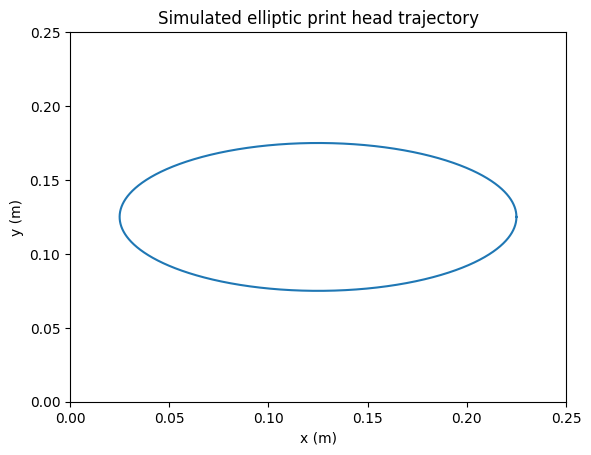

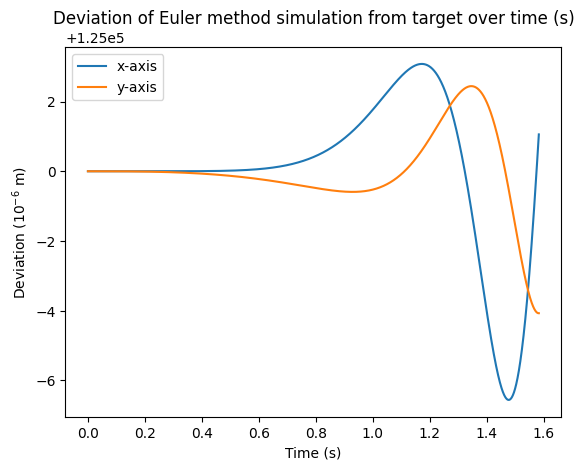

In [3]:
dt = 0.00001
t_end = (2*np.pi)**0.25
t = 0.0

# state initial conditions
x = 0.25/2 + semi_xaxis
xlist = []
x_d = 0.0
i_x = 0.0
x_x = np.array([[x_d], [x], [i_x]])

y = 0.25/2 + 0.0
ylist = []
y_d = 0.0
i_y = 0.0
x_y = np.array([[y_d], [y], [i_y]])


# coordinates as numerically calculated, given targets will be x_u and y_u
x_sim = x
y_sim = y
x_simlist = []
y_simlist = []

for t in np.arange(0, t_end, dt):
    x_simlist.append(x_sim)
    y_simlist.append(y_sim)
    
    x_u = semi_xaxis * np.cos(t**4)
    xlist.append(x_u)
    x_u_d = -4*t**3 * semi_xaxis * np.sin(t**4)
    x_u_dd = -12*t**2 * semi_xaxis * np.sin(t**4) - 16*t**6 * semi_xaxis * np.cos(t**4)
    x_u_ddd = -24*t * semi_xaxis * np.sin(t**4) - 144*t**5 * semi_xaxis * np.cos(t**4) + 64*t**9 * semi_xaxis * np.sin(t**4)

    y_u = semi_yaxis * np.sin(t**4)
    ylist.append(y_u)
    y_u_d = 4*t**3 * semi_yaxis * np.cos(t**4)
    y_u_dd = 12*t**2 * semi_yaxis * np.cos(t**4) - 16*t**6 * semi_yaxis * np.sin(t**4)
    y_u_ddd = 24*t * semi_yaxis * np.cos(t**4) - 144*t**5 * semi_yaxis * np.sin(t**4) - 64*t**9 * semi_yaxis * np.cos(t**4)

    u_x = (L_m*(2*J_m + m*r_m**2)*x_u_ddd + (L_m*mu_x*r_m**2 + R_m*(2*J_m + m*r_m**2))*x_u_dd + (R_m*mu_x*r_m**2 + 2*K_m**2)*x_u_d) / (r_m*K_m)
    u_y = (L_m*(2*J_m + m*r_m**2)*y_u_ddd + (L_m*mu_y*r_m**2 + R_m*(2*J_m + m*r_m**2))*y_u_dd + (R_m*mu_y*r_m**2 + 2*K_m**2)*y_u_d) / (r_m*K_m)

    x_x_d = A_x@x_x + B*u_x
    x_y_d = A_y@x_y + B*u_y

    # Apply Euler method
    x_x += x_x_d * dt
    x_y += x_y_d * dt
    x_sim = x_x[1][0]
    y_sim = x_y[1][0]

plt.title("Simulated elliptic print head trajectory")
plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.xlim(0, 0.25)
plt.ylim(0, 0.25)
plt.plot(x_simlist, y_simlist)
plt.show()

plt.title("Deviation of Euler method simulation from target over time (s)")
plt.xlabel("Time (s)")
plt.ylabel("Deviation ($10^{-6}$ m)")
plt.plot(np.arange(0, t_end, dt), (np.array(x_simlist) - np.array(xlist))*10**6, label='x-axis')
plt.plot(np.arange(0, t_end, dt), (np.array(y_simlist) - np.array(ylist))*10**6, label='y-axis')
plt.legend()
plt.show()

Of course, this particular method accelerates very quickly to unrealistic speeds, but it demonstrates that our tracking works with a nice algebraic function.

We will now draw a rectangle. This should be relatively simple given that the friction in positive and negative x- and y- directions are symmetric. We will run it as follows: 
- Apply +6V to u_y for 1 second.
- Wait 10 seconds for friction to stop the toolhead.
- Apply +6V to u_x for 1 second.
- Wait 10 seconds.
- Apply -6V to u_y for 1 second.
- Wait 10 seconds.
- Apply -6V to u_x for 1 seconds.
- Wait 10 seconds.
- We should have finished where we started.

In [4]:
from matplotlib.animation import FuncAnimation

dt = 0.001
t_end = 44
t = 0.0

t_simlist= np.arange(t, t_end, dt)

# state initial conditions and state vectors
x = 0.0
x_d = 0.0
i_x = 0.0
x_x = np.array([[x_d], [x], [i_x]])

y = 0.0
y_d = 0.0
i_y = 0.0
x_y = np.array([[y_d], [y], [i_y]])


# coordinates as numerically calculated, given targets will be x_u and y_u
x_sim = 0.0
y_sim = 0.0
x_simlist = []
y_simlist = []

for t in np.arange(0, t_end, dt):
    x_simlist.append(x_sim)
    y_simlist.append(y_sim)
    
    if(t < 1):
        u_x = 0
        u_y = 6
    elif(t < 11):
        u_x = 0
        u_y = 0
    elif(t < 12):
        u_x = 6
        u_y = 0
    elif(t < 22):
        u_x = 0
        u_y = 0
    elif(t < 23):
        u_x = 0
        u_y = -6
    elif(t < 33):
        u_x = 0
        u_y = 0
    elif(t < 34):
        u_x = -6
        u_y = 0
    else:
        u_x = 0
        u_y = 0

    x_x_d = A_x@x_x + B*u_x
    x_y_d = A_y@x_y + B*u_y

    # Apply Euler method
    x_x += x_x_d * dt
    x_y += x_y_d * dt
    x_sim = x_x[1][0]
    y_sim = x_y[1][0]

#plt.plot(x_simlist, y_simlist)
#plt.show()


fig, ax = plt.subplots()

point, = ax.plot([], [], 'ro')
trail, = ax.plot([], [], 'b-')

ax.set_title("Euler simulation of a rectangular print head trajectory")
ax.set_xlim(min(x_simlist)-0.01, max(x_simlist)*1.1)
ax.set_ylim(min(y_simlist)-0.01, max(y_simlist)*1.1)
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")

def update(frame):
    point.set_data([x_simlist[frame]], [y_simlist[frame]])
    trail.set_data(x_simlist[:frame+1], y_simlist[:frame+1])
    return point, trail

ani = FuncAnimation(fig, update, frames=range(0, len(t_simlist), 50),
                    interval=50, blit=True)

plt.close()

from IPython.display import HTML
HTML(ani.to_jshtml())

Animation size has reached 20975415 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.
